# Cancer Gene Expression Analysis: DEG demo (practice data)

**FYP group:** Hira Afzal (SP23-BSI-020), Hamna Nasim (SP23-BSI-017), Namra Munir Khokhar (SP23-BSI-040)  
COMSATS University Islamabad, Department of Biosciences, BS Bioinformatics

This notebook is the Python version of the differential expression step we practised in Galaxy (DESeq2).  
**Important:** the data below is **simulated practice data**, not real patients. It is only used to build and test the code. Real GEO/TCGA data will be used later.

**Plan of this notebook**
1. Create a small count table (5 cancer and 5 healthy samples, 10 genes including apoptosis genes)
2. Find differentially expressed genes (DEGs): `padj < 0.05` and `|log2FC| > 1`
3. Draw a volcano plot, marking apoptosis genes with `*`

## Step 1 and 2: Count table and DEGs

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

np.random.seed(42)

genes = ["TP53", "BAX", "BCL2", "CASP3", "MYC", "EGFR", "GAPDH", "ACTB", "VEGFA", "CDKN1A"]
base = [200, 150, 120, 100, 80, 90, 1000, 1200, 60, 70]
cancer_factor = [0.8, 0.4, 3.0, 0.4, 4.0, 2.5, 1.0, 1.0, 1.0, 1.0]

samples = ["C1", "C2", "C3", "C4", "C5", "H1", "H2", "H3", "H4", "H5"]  # C = cancer, H = healthy

data = {}
for s in samples:
    is_cancer = s.startswith("C")
    data[s] = [np.random.poisson(b * (f if is_cancer else 1)) for b, f in zip(base, cancer_factor)]
counts = pd.DataFrame(data, index=genes)

log_counts = np.log2(counts + 1)
cancer = log_counts[["C1", "C2", "C3", "C4", "C5"]]
healthy = log_counts[["H1", "H2", "H3", "H4", "H5"]]

result = pd.DataFrame(index=genes)
result["log2FC"] = cancer.mean(axis=1) - healthy.mean(axis=1)
result["p_value"] = stats.ttest_ind(cancer, healthy, axis=1).pvalue
result["padj"] = multipletests(result["p_value"], method="fdr_bh")[1]
result["DEG"] = (result["padj"] < 0.05) & (result["log2FC"].abs() > 1)

print(counts)
print()
print(result.round(4).sort_values("padj"))

          C1    C2    C3    C4    C5    H1    H2    H3    H4    H5
TP53     155   158   185   171   161   192   191   207   178   193
BAX       65    52    62    57    56   139   154   150   169   155
BCL2     338   365   329   384   390   131    96   125   115   125
CASP3     42    42    25    37    38    98   116   106   114    84
MYC      340   310   314   310   305    68    69    97    84    73
EGFR     209   233   241   235   215   110    95    85    93   104
GAPDH    982   957   979  1045  1059  1002   974  1056   952  1029
ACTB    1193  1175  1157  1153  1213  1186  1187  1174  1205  1208
VEGFA     62    56    67    66    68    81    63    68    63    52
CDKN1A    65    71    75    77    82    70    65    71    75    64

        log2FC  p_value    padj    DEG
BAX    -1.3796   0.0000  0.0000   True
BCL2    1.6060   0.0000  0.0000   True
CASP3  -1.4820   0.0000  0.0000   True
MYC     2.0121   0.0000  0.0000   True
EGFR    1.2133   0.0000  0.0000   True
TP53   -0.2116   0.0062  0.0

**How to read the result table**
- `log2FC`: positive = higher in cancer, negative = lower in cancer
- `padj`: adjusted p-value (smaller is better; below 0.05 means the difference is unlikely to be chance)
- `DEG`: True if the gene passes both cut-offs

In this practice data, BCL2 (blocks apoptosis) is higher in cancer, while BAX and CASP3 (cause apoptosis) are lower.

## Step 3: Volcano plot

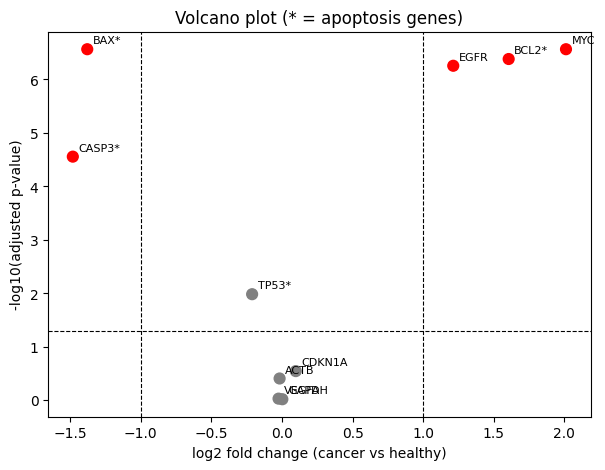

In [2]:
import matplotlib.pyplot as plt

result["-log10(padj)"] = -np.log10(result["padj"] + 1e-300)
apoptosis = ["TP53", "BAX", "BCL2", "CASP3"]

plt.figure(figsize=(7, 5))
colors = result["DEG"].map({True: "red", False: "grey"})
plt.scatter(result["log2FC"], result["-log10(padj)"], c=colors, s=60)

for gene in result.index:
    marker = "*" if gene in apoptosis else ""
    plt.annotate(gene + marker, (result.loc[gene, "log2FC"], result.loc[gene, "-log10(padj)"]),
                 fontsize=8, xytext=(4, 4), textcoords="offset points")

plt.axvline(1, linestyle="--", color="black", linewidth=0.8)
plt.axvline(-1, linestyle="--", color="black", linewidth=0.8)
plt.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=0.8)
plt.xlabel("log2 fold change (cancer vs healthy)")
plt.ylabel("-log10(adjusted p-value)")
plt.title("Volcano plot (* = apoptosis genes)")
plt.show()

**Reading the plot:** red points are DEGs. Right side = higher in cancer, left side = lower in cancer. Points higher up are statistically stronger.

## Next steps
- Replace the simulated table with a real count table (from Galaxy featureCounts or a GEO/TCGA dataset)
- Add heatmap and apoptosis pathway analysis
- Build the machine learning model (cancer vs healthy)

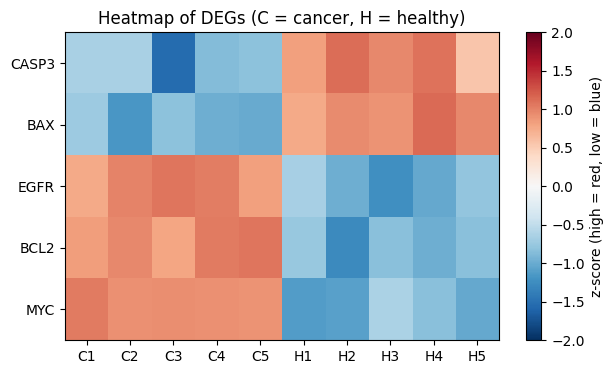

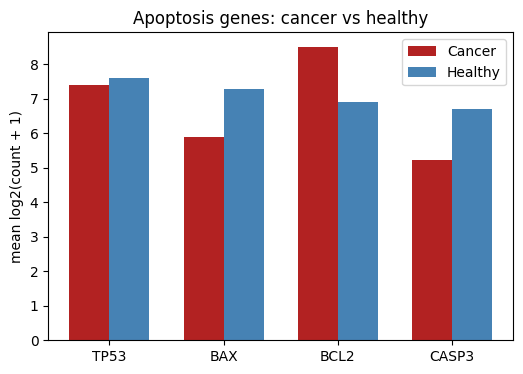

In [3]:
import matplotlib.pyplot as plt

# Heatmap of DEGs
deg_genes = result[result["DEG"]].sort_values("log2FC").index
heat = log_counts.loc[deg_genes]
heat_z = heat.sub(heat.mean(axis=1), axis=0).div(heat.std(axis=1), axis=0)

plt.figure(figsize=(7, 4))
plt.imshow(heat_z, cmap="RdBu_r", aspect="auto", vmin=-2, vmax=2)
plt.colorbar(label="z-score (high = red, low = blue)")
plt.xticks(range(len(heat_z.columns)), heat_z.columns)
plt.yticks(range(len(heat_z.index)), heat_z.index)
plt.title("Heatmap of DEGs (C = cancer, H = healthy)")
plt.show()

# Apoptosis genes: cancer vs healthy
apoptosis = ["TP53", "BAX", "BCL2", "CASP3"]
mean_c = log_counts.loc[apoptosis, ["C1", "C2", "C3", "C4", "C5"]].mean(axis=1)
mean_h = log_counts.loc[apoptosis, ["H1", "H2", "H3", "H4", "H5"]].mean(axis=1)

x = np.arange(len(apoptosis))
w = 0.35
plt.figure(figsize=(6, 4))
plt.bar(x - w/2, mean_c, w, label="Cancer", color="firebrick")
plt.bar(x + w/2, mean_h, w, label="Healthy", color="steelblue")
plt.xticks(x, apoptosis)
plt.ylabel("mean log2(count + 1)")
plt.title("Apoptosis genes: cancer vs healthy")
plt.legend()
plt.show()